# Módulo 16 — Hedge dinâmico e síntese

**Curso:** Derivativos com Python, a partir de *Derivatives Analytics with Python* (Y. Hilpisch, Wiley, 2015).
**Este módulo cobre:** capítulos 13 e 14 do livro.

## O que você vai conseguir fazer ao final

1. Montar uma carteira replicante autofinanciável e provar que o P&L médio do hedge é zero sob $Q$.
2. Medir como o erro de hedge diminui com a frequência de rebalanceamento.
3. Estimar deltas a partir de simulações sem que o ruído domine o resultado.
4. Fazer o hedge de uma put americana com os deltas da regressão do LSM, fora da amostra.
5. Explicar de onde vem o "lucro médio" do hedge no BCC97 do livro.
6. Separar risco de volatilidade e risco de salto, e medir o que uma opção adicional na carteira resolve.

## Onde estamos

O preço de um derivativo é o custo da sua replicação. Os Módulos 1 a 15 trataram do preço; este trata da replicação. É o teste final do modelo: um modelo pode precificar bem as opções do mercado e ainda assim deixar o vendedor exposto, se os riscos que ele carrega não podem ser cobertos pelos instrumentos disponíveis.

## 0. Preparação

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.interpolate as sci
from scipy.integrate import simpson
from scipy.optimize import brentq
from scipy.interpolate import RegularGridInterpolator
import warnings
warnings.simplefilter("ignore", np.exceptions.RankWarning)
from scipy.stats import norm
from IPython.display import display

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a84"
RAMPA = ["#86b6ef", "#2a78d6", "#104281"]

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2.0, "legend.frameon": False,
    "font.size": 10,
})


def f3(x):
    """Formata com três casas decimais no padrão brasileiro."""
    return f"{x:,.3f}".replace(",", "§").replace(".", ",").replace("§", ".")


def tabela(df):
    """Exibe um DataFrame com os números reais em três casas decimais."""
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "n/d" if np.isnan(v) else f3(v)
        return v
    display(df.map(fmt))


_checks = {"n": 0}


def ok(condicao, mensagem):
    """Verificação do laboratório: interrompe o notebook se a conta não fechar."""
    assert bool(condicao), f"FALHOU: {mensagem}"
    _checks["n"] += 1
    print(f"OK — {mensagem}")


def bsm(S, K, T, r, sig):
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * T) / (sig * np.sqrt(T))
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d1 - sig * np.sqrt(T))


def vega_bsm(S, K, T, r, sig):
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * T) / (sig * np.sqrt(T))
    return S * norm.pdf(d1) * np.sqrt(T)


def vol_impl(preco, S, K, T, r):
    piso = max(S - K * np.exp(-r * T), 0.0)
    if not (piso + 1e-12 < preco < S):
        return np.nan
    return brentq(lambda s: float(bsm(S, K, T, r, s)) - preco, 1e-4, 4.0)


def cf_heston(u, T, v0, kappa, theta, sigma, rho):
    """Função característica de ln(S_T/S_0) - rT no Heston, forma estável (Módulo 11)."""
    xi = kappa - rho * sigma * 1j * u
    d = np.sqrt(xi**2 + sigma**2 * (1j * u + u**2))
    g = (xi - d) / (xi + d)
    e = np.exp(-d * T)
    A = kappa * theta / sigma**2 * ((xi - d) * T - 2 * np.log((1 - g * e) / (1 - g)))
    B = (xi - d) / sigma**2 * (1 - e) / (1 - g * e)
    return np.exp(A + B * v0)


def cf_saltos(u, T, lam, mu, delta):
    """Parte de saltos de Merton, com o drift compensado (11.13)-(11.14)."""
    omega = -lam * (np.exp(mu + 0.5 * delta**2) - 1)
    return np.exp((1j * u * omega + lam * (np.exp(1j * u * mu - 0.5 * u**2 * delta**2) - 1)) * T)


U_FINO = np.linspace(0, 2000, 200_001)
U_CAL = np.linspace(0, 300, 3001)


def calls(S0, K, T, r, heston, saltos=None, u=U_CAL):
    """Calls europeias pela fórmula de Lewis (11.12), vetorizada em (K, T, r) do mesmo tamanho.
    heston = (v0, κ_v, θ_v, σ_v, ρ); saltos = (λ, μ_J, δ) ou None."""
    K, T, r = (np.atleast_1d(np.asarray(x, float)) for x in (K, T, r))
    k = np.log(S0 / K) + r * T
    phi = cf_heston(u[None, :] - 0.5j, T[:, None], *heston)
    if saltos is not None:
        phi = phi * cf_saltos(u[None, :] - 0.5j, T[:, None], *saltos)
    h = np.exp(1j * u[None, :] * k[:, None]) * phi
    integral = simpson(h.real / (u**2 + 0.25), x=u, axis=1)
    return S0 - np.sqrt(S0 * K) * np.exp(-0.5 * r * T) / np.pi * integral


def zcb_cir(r0, kappa, theta, sigma, T):
    """Zero-cupom no CIR, (11.7)-(11.9) com t = 0."""
    g = np.sqrt(kappa**2 + 2 * sigma**2)
    e = np.exp(g * T) - 1
    D = 2 * g + (kappa + g) * e
    return (2 * g * np.exp((kappa + g) * T / 2) / D) ** (2 * kappa * theta / sigma**2) * np.exp(-2 * e / D * r0)


def fator_ft(xh, kappa, theta, sigma, dt, z):
    """Um passo Full Truncation (Módulo 12): devolve (x truncado, x̃ auxiliar)."""
    p = np.maximum(xh, 0)
    xh = xh + kappa * (theta - p) * dt + sigma * np.sqrt(p * dt) * z
    return np.maximum(xh, 0), xh


print("Ambiente pronto.")

Ambiente pronto.


---
## 1. Hedge dinâmico: a teoria em quatro passos

**Livro: §13.1**

**Passo 1 — o delta.** Para uma put $P(t, S)$, $\Delta_t = \partial P/\partial S$. Carregar $-\Delta_t$ unidades do índice junto com a put anula a variação de primeira ordem: $dP - \Delta\,dS = 0$ para movimentos pequenos de $S$.

**Passo 2 — a carteira replicante.** Com $\Delta_t$ ações e $\gamma_t = P_t - \Delta_tS_t$ no título sem risco, a carteira vale $P_t$. Ela é **autofinanciável** se, a cada rebalanceamento, a compra de ações é paga pela venda de título e vice-versa:

$$\Delta_tS_t + \gamma_tB_t = \Delta_{t - \Delta t}S_t + \gamma_{t - \Delta t}B_t.$$

**Passo 3 — a média do erro.** Seja $\Pi_t$ o valor da carteira autofinanciável, iniciada em $\Pi_0 = P_0$. Descontada, ela é uma soma de termos $\Delta_s\,d\tilde S_s$, onde $\tilde S$ é o índice descontado. Se $\tilde S$ é martingal sob $Q$, a carteira descontada também é, qualquer que seja a regra de delta. Então

$$\mathbb{E}^Q\big[\tilde\Pi_\tau - \tilde h_\tau\big] = P_0 - \mathbb{E}^Q[\tilde h_\tau].$$

Se $P_0$ é o preço justo para a regra de exercício $\tau$ usada, a **média do P&L descontado é zero**, quer o hedge seja bom ou ruim. Numa simulação sob $Q$, um P&L médio diferente de zero só pode vir de preço errado ou de simulação errada. Hedge reduz **variância**, não cria média.

**Passo 4 — o tamanho do erro.** Com rebalanceamento a cada $\Delta t = T/N$ no BSM, o erro de cada intervalo vem do gama: $\tfrac12\Gamma S^2(\sigma^2\Delta t - (\Delta S/S)^2)$. Somando $N$ termos de média zero e variância proporcional a $\Delta t^2$, o desvio-padrão do P&L cai como $1/\sqrt N$. Derman e Kamal (1999) dão a aproximação

$$\text{dp(P\&L)} \approx \sqrt{\frac{\pi}{4}}\,\frac{\sigma\,\mathcal V}{\sqrt N}, \qquad \mathcal V = \text{vega da opção}.$$

### Laboratório 1 — Hedge de uma put europeia no BSM

Put no dinheiro, $S_0 = K = 100$, $T = 1$, $r = 5\%$, $\sigma = 20\%$, hedge com o delta exato do BSM, 20.000 trajetórias.

In [2]:
S0b, Kb, Tb, rb, sigb = 100.0, 100.0, 1.0, 0.05, 0.2


def put_bsm(S, K, T, r, sig):
    return bsm(S, K, T, r, sig) - S + K * np.exp(-r * T)


def delta_put_bsm(S, K, T, r, sig):
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * T) / (sig * np.sqrt(T))
    return norm.cdf(d1) - 1


def hedge_bsm_europeia(N, I, rng):
    dt = Tb / N
    S = np.full(I, S0b)
    d = delta_put_bsm(S, Kb, Tb, rb, sigb)
    B = put_bsm(S0b, Kb, Tb, rb, sigb) - d * S
    for j in range(1, N + 1):
        S = S * np.exp((rb - 0.5 * sigb**2) * dt + sigb * np.sqrt(dt) * rng.standard_normal(I))
        B = B * np.exp(rb * dt)
        port = d * S + B
        if j < N:
            d_novo = delta_put_bsm(S, Kb, Tb - j * dt, rb, sigb)
            B = port - d_novo * S                       # autofinanciável
            d = d_novo
    return (port - np.maximum(Kb - S, 0)) * np.exp(-rb * Tb)


rng = np.random.default_rng(13)
vega0 = vega_bsm(S0b, Kb, Tb, rb, sigb)
linhas = []
for N in [12, 50, 200, 800]:
    pl = hedge_bsm_europeia(N, 20_000, rng)
    linhas.append((N, pl.mean(), pl.std() / np.sqrt(len(pl)), pl.std(), np.sqrt(np.pi / 4) * sigb * vega0 / np.sqrt(N)))
tab1 = pd.DataFrame(linhas, columns=["rebalanceamentos N", "P&L médio", "erro-padrão da média", "dp do P&L", "Derman-Kamal"])
tabela(tab1)
incl = np.polyfit(np.log(tab1["rebalanceamentos N"]), np.log(tab1["dp do P&L"]), 1)[0]
print("put BSM:", f3(put_bsm(S0b, Kb, Tb, rb, sigb)), "| inclinação log-log do dp:", f3(incl))

ok(np.all(np.abs(tab1["P&L médio"]) < 3 * tab1["erro-padrão da média"] + 0.01), "o P&L médio é zero, para qualquer N")
ok(abs(incl + 0.5) < 0.05, "o desvio-padrão do P&L cai como 1/√N")
ok(np.all(np.abs(tab1["dp do P&L"] / tab1["Derman-Kamal"] - 1) < 0.15), "e a fórmula de Derman-Kamal acerta a menos de 15%")

,rebalanceamentos N,P&L médio,erro-padrão da média,dp do P&L,Derman-Kamal
0,12,"-0,006","0,013","1,852","1,920"
1,50,"-0,003","0,007","0,923","0,941"
2,200,"0,001","0,003","0,462","0,470"
3,800,"0,000","0,002","0,237","0,235"


put BSM: 5,574 | inclinação log-log do dp: -0,491
OK — o P&L médio é zero, para qualquer N
OK — o desvio-padrão do P&L cai como 1/√N
OK — e a fórmula de Derman-Kamal acerta a menos de 15%


Num mundo BSM, o hedge funciona como a teoria promete: a média é zero e o erro some com rebalanceamentos mais frequentes. Quadruplicar a frequência corta o erro pela metade.

---
## 2. Deltas tirados de uma simulação

**Livro: §13.2, equações (13.1) e (13.2)**

Para uma put americana não há fórmula. O livro estima o delta inicial pela diferença de dois preços LSM:

$$\Delta_0 \approx \frac{P^{LSM}(S_0 + 0{,}01) - P^{LSM}(S_0)}{0{,}01}.$$

No script da §13.5.1, cada um dos dois preços vem de uma simulação **com números aleatórios diferentes** (a semente é fixada uma vez, antes das duas chamadas). Isso é um problema sério: o erro de Monte Carlo de cada preço, da ordem de 0,02, é dividido por 0,01. O ruído do delta fica da ordem de 2, quando o delta verdadeiro está entre $-1$ e 0.

O remédio é usar **números aleatórios comuns**: as duas simulações com os mesmos choques. Então os erros de Monte Carlo dos dois preços são quase iguais e se cancelam na diferença. Uma alternativa sem simulação extra é derivar a própria regressão do LSM em $S$, que é o que o livro faz nos instantes seguintes (13.2).

### Laboratório 2 — Delta inicial da put americana de Longstaff e Schwartz

$S_0 = 36$, $K = 40$, $T = 1$, $r = 6\%$, $\sigma = 20\%$, 50 datas de exercício, 50.000 trajetórias, regressão polinomial de grau 9 em todas as trajetórias (como no script). A referência é a árvore CRR com 2.000 passos (Módulo 6).

In [3]:
S0a, Ka, Ta, ra, siga, Ma = 36.0, 40.0, 1.0, 0.06, 0.2, 50


def crr_put_americana(S0, K, T, r, sig, M):
    dt = T / M
    u = np.exp(sig * np.sqrt(dt)); d = 1 / u
    q = (np.exp(r * dt) - d) / (u - d); desc = np.exp(-r * dt)
    j = np.arange(M + 1)
    V = np.maximum(K - S0 * u**j * d ** (M - j), 0.0)
    for t in range(M - 1, -1, -1):
        V = desc * (q * V[1:] + (1 - q) * V[:-1])
        j = np.arange(t + 1)
        V = np.maximum(V, K - S0 * u**j * d ** (t - j))
        if t == 1:
            V1 = V.copy()
    return V[0], (V1[1] - V1[0]) / (S0 * (u - d))


def lsm_bsm(S0, Z, regra_livro=True, D=9):
    """LSM do script da §13.5.1. Z: normais (M, I). Devolve preço, trajetórias, coeficientes e matriz de exercício."""
    M, I = Z.shape
    dt = Ta / M
    df = np.exp(-ra * dt)
    S = S0 * np.exp(np.vstack([np.zeros(I), np.cumsum((ra - 0.5 * siga**2) * dt + siga * np.sqrt(dt) * Z, axis=0)]))
    h = np.maximum(Ka - S, 0)
    V = h[-1].copy()
    rg = np.zeros((M + 1, D + 1))
    ex = np.zeros((M + 1, I), dtype=bool)
    for t in range(M - 1, 0, -1):
        rg[t] = np.polyfit(S[t], V * df, D)
        C = np.maximum(np.polyval(rg[t], S[t]), 0.0)
        ex[t] = (h[t] >= C) if regra_livro else ((h[t] > C) & (h[t] > 0))
        V = np.where(ex[t], h[t], V * df)
    return V.mean() * df, S, rg, ex


P_crr, D_crr = crr_put_americana(S0a, Ka, Ta, ra, siga, 2000)
rng = np.random.default_rng(50000)
ds = 0.01
d_indep, d_crn, d_reg, precos = [], [], [], []
for _ in range(12):
    Z1 = rng.standard_normal((Ma, 50_000))
    Z2 = rng.standard_normal((Ma, 50_000))
    V_up, _, rg, _ = lsm_bsm(S0a + ds, Z1)
    V_0, _, _, _ = lsm_bsm(S0a, Z2)
    V_0crn, _, _, _ = lsm_bsm(S0a, Z1)
    d_indep.append((V_up - V_0) / ds)
    d_crn.append((V_up - V_0crn) / ds)
    d_reg.append(np.polyval(np.polyder(rg[1]), S0a))
    precos.append(V_0)
tab2 = pd.DataFrame({"método": ["dois LSM independentes (livro)", "números aleatórios comuns", "derivada da regressão em t = Δt"],
                     "delta médio": [np.mean(d_indep), np.mean(d_crn), np.mean(d_reg)],
                     "desvio-padrão (12 repetições)": [np.std(d_indep), np.std(d_crn), np.std(d_reg)]})
tabela(tab2)
print("CRR (2.000 passos): preço", f3(P_crr), "| delta", f3(D_crr), "| LSM médio:", f3(np.mean(precos)))

t2 = tab2.set_index("método")["desvio-padrão (12 repetições)"]
ok(t2["dois LSM independentes (livro)"] > 0.5, "com simulações independentes, o delta tem desvio-padrão acima de 0,5: é ruído")
ok(t2["números aleatórios comuns"] < 0.1, "com números aleatórios comuns, o desvio-padrão cai abaixo de 0,1")
ok(t2["dois LSM independentes (livro)"] > 10 * t2["números aleatórios comuns"], "uma redução de mais de 10 vezes")
ok(abs(np.mean(d_crn) - D_crr) < 0.05 and abs(np.mean(d_reg) - D_crr) < 0.05, "os dois métodos corretos acertam o delta da árvore a menos de 0,05")

,método,delta médio,desvio-padrão (12 repetições)
0,dois LSM independentes (livro),"0,908","1,631"
1,números aleatórios comuns,"-0,714","0,081"
2,derivada da regressão em t = Δt,"-0,705","0,044"


CRR (2.000 passos): preço 4,487 | delta -0,697 | LSM médio: 4,462
OK — com simulações independentes, o delta tem desvio-padrão acima de 0,5: é ruído
OK — com números aleatórios comuns, o desvio-padrão cai abaixo de 0,1
OK — uma redução de mais de 10 vezes
OK — os dois métodos corretos acertam o delta da árvore a menos de 0,05


O delta inicial do livro, $-0{,}587$, é um sorteio de uma distribuição muito larga. Com números aleatórios comuns, ou derivando a regressão, o delta fica estável e perto da árvore. Os números comuns não zeram o ruído: com $S_0$ deslocado, algumas decisões de exercício mudam, e a diferença deixa de ser suave. A derivada da regressão evita esse problema e não custa nenhuma simulação extra.

---
## 3. Hedge da put americana no BSM com os deltas da regressão

**Livro: §13.2 e §13.5.2**

O livro reaproveita os coeficientes da regressão do LSM: em cada data, o delta é a derivada do polinômio de continuação em $S_t$, e a decisão de exercício é a da regra do LSM. O P&L é calculado nas **mesmas** trajetórias usadas na regressão.

Dois cuidados que fazemos aqui:

1. **Fora da amostra.** Treinamos a regressão em 50.000 trajetórias e fazemos o hedge em outras 10.000. Nas mesmas trajetórias, a regra de exercício "conhece o futuro" e o P&L sai otimista (Módulo 9).
2. **A regra de exercício do script.** O script exerce quando $h_t \ge \hat C_t$, com $\hat C_t$ truncado em zero. Fora do dinheiro, $h_t = 0$; onde o polinômio fica negativo, $\hat C_t = 0$; e $0 \ge 0$ marca um **exercício** de uma put sem valor intrínseco. Na contagem do hedge, isso encerra a operação antes da hora. O correto é exigir $h_t > \hat C_t$ e $h_t > 0$.

### Laboratório 3 — P&L do hedge, regra do livro e regra corrigida

In [4]:
def hedge_americana_bsm(Z_trein, Z_teste, regra_livro):
    V0, _, rg, _ = lsm_bsm(S0a, Z_trein, regra_livro)
    M, I = Z_teste.shape
    dt = Ta / M
    S = S0a * np.exp(np.vstack([np.zeros(I), np.cumsum((ra - 0.5 * siga**2) * dt + siga * np.sqrt(dt) * Z_teste, axis=0)]))
    h = np.maximum(Ka - S, 0)
    d = np.full(I, np.polyval(np.polyder(rg[1]), S0a))
    B = V0 - d * S0a
    vivo = np.ones(I, dtype=bool)
    pl = np.zeros(I)
    falso = np.zeros(I, dtype=bool)
    for t in range(1, M + 1):
        B = B * np.exp(ra * dt)
        port = d * S[t] + B
        if t == M:
            ex = vivo.copy()
        else:
            C = np.maximum(np.polyval(rg[t], S[t]), 0.0)
            regra = (h[t] >= C) if regra_livro else ((h[t] > C) & (h[t] > 0))
            ex = vivo & regra
            falso |= ex & (h[t] == 0)
        pl[ex] = (port[ex] - h[t, ex]) * np.exp(-ra * t * dt)
        vivo &= ~ex
        if t < M:
            d_novo = np.clip(np.polyval(np.polyder(rg[t]), S[t]), -1, 0)
            B = port - d_novo * S[t]
            d = d_novo
    return V0, pl, falso.mean()


rng = np.random.default_rng(7)
Z_trein = rng.standard_normal((Ma, 50_000))
Z_teste = rng.standard_normal((Ma, 10_000))
linhas = []
for nome, regra in [("regra do livro (h ≥ Ĉ)", True), ("regra corrigida (h > Ĉ e h > 0)", False)]:
    V0, pl, frac = hedge_americana_bsm(Z_trein, Z_teste, regra)
    linhas.append((nome, V0, pl.mean(), pl.std() / np.sqrt(len(pl)), pl.std(), np.percentile(pl, 1), pl.min(), pl.max(), 100 * frac))
tab3 = pd.DataFrame(linhas, columns=["exercício", "preço LSM", "P&L médio", "erro-padrão", "dp do P&L",
                                     "percentil 1%", "mínimo", "máximo", "% 'exercícios' sem valor"])
tabela(tab3)

t3 = tab3.set_index("exercício")
ok(t3.loc["regra do livro (h ≥ Ĉ)", "% 'exercícios' sem valor"] > 5, "a regra do livro 'exerce' sem valor intrínseco em mais de 5% das trajetórias")
ok(t3.loc["regra corrigida (h > Ĉ e h > 0)", "% 'exercícios' sem valor"] == 0, "a regra corrigida nunca exerce fora do dinheiro")
ok(abs(t3.loc["regra corrigida (h > Ĉ e h > 0)", "P&L médio"]) < 3 * t3.loc["regra corrigida (h > Ĉ e h > 0)", "erro-padrão"] + 0.02,
   "com a regra corrigida e fora da amostra, o P&L médio é zero")

,exercício,preço LSM,P&L médio,erro-padrão,dp do P&L,percentil 1%,mínimo,máximo,% 'exercícios' sem valor
0,regra do livro (h ≥ Ĉ),"4,470","0,014","0,004","0,371","-1,010","-2,066","2,109","22,100"
1,regra corrigida (h > Ĉ e h > 0),"4,483","0,011","0,004","0,401","-1,134","-2,529","2,114","0,000"


OK — a regra do livro 'exerce' sem valor intrínseco em mais de 5% das trajetórias
OK — a regra corrigida nunca exerce fora do dinheiro
OK — com a regra corrigida e fora da amostra, o P&L médio é zero


Com a regra corrigida, o hedge com deltas da regressão funciona bem no BSM: média zero e desvio-padrão comparável ao da put europeia do Laboratório 1 com 50 rebalanceamentos. Com a regra do script, cerca de um quinto das trajetórias "termina" quando a put ainda está viva, fora do dinheiro; o P&L dessas trajetórias é medido na hora errada. Neste exemplo o efeito nas estatísticas é pequeno, porque essas puts valem quase nada quando a regra dispara; mas a contagem de exercícios, e qualquer análise da fronteira de exercício feita com essa regra, sai errada.

---
## 4. Hedge da put americana no BCC97

**Livro: §13.3 e §13.5.3 a §13.5.4**

O livro repete o estudo no BCC97 calibrado (put no dinheiro, $T = 1$, 50 passos) com 11 funções de base em $(S, v, r)$ e diferenças finitas de segunda ordem para o delta. Resultado: P&L médio de $+4{,}34$, mediana de 15 e mínimo de $-1.014$. O livro conclui que o lucro médio "justificaria" aplicar a estratégia a uma carteira grande, e que o risco de salto seria "diversificável".

Pelo Passo 3 da Seção 1, um P&L médio positivo numa simulação sob $Q$ não é lucro: é inconsistência entre o preço e a simulação. E a simulação do livro carrega os vieses do Módulo 15 (`v[t]` e compensador ausente), que fazem o índice descontado **não** ser martingal. Uma posição vendida em delta (put → delta negativo) ganha quando o índice cai mais do que deveria.

### Laboratório 4 — De onde vem o lucro médio

Mesmo procedimento do livro (LSM com 11 bases treinado em 50.000 trajetórias; delta pela derivada analítica da regressão em $S$), hedge **fora da amostra** em 20.000 trajetórias, para:

* parâmetros do livro com o simulador do livro;
* parâmetros do livro com o esquema exato do Módulo 15;
* o Bates sintético dos Módulos 13 a 15 com o esquema exato.

In [5]:
S0 = 3225.93
CIR = dict(r0=0.02, kappa=0.5, theta=0.045, sigma=0.08)
BATES = np.array([3.0, 0.04, 0.5, -0.7, 0.03, 0.15, -0.15, 0.10])
LIVRO = np.array([22.212, 0.025, 0.952, -0.999, 0.036, 0.008, -0.501, 0.000])
LIVRO_CFG = dict(olhar_frente=True, compensador=False, aditivo=True, mm=True)


def simular(p, T, M, I, rng, cir=None, olhar_frente=False, compensador=True, aditivo=False, mm=False):
    """Trajetórias (S, v, r) do BCC97 e o número de saltos por trajetória (simulador do Módulo 15)."""
    cir = CIR if cir is None else cir
    kappa, theta, sigma, rho, v0, lam, mu, delta = p
    dt = T / M
    Z = rng.standard_normal((4, M, I // 2)); Z = np.concatenate([Z, -Z], axis=2)
    if mm:
        Z = (Z - Z.mean(axis=(1, 2), keepdims=True)) / Z.std(axis=(1, 2), keepdims=True)
    N = rng.poisson(lam * dt, (M, I))
    rJ = lam * (np.exp(mu + 0.5 * delta**2) - 1)
    r = np.full(I, cir["r0"]); rh = r.copy(); v = np.full(I, v0); vh = v.copy(); S = np.full(I, S0)
    Sp, vp, rp = [S], [v], [r]
    for t in range(M):
        z1 = Z[1, t]; z2 = rho * z1 + np.sqrt(1 - rho**2) * Z[2, t]
        if cir["sigma"] > 0:
            r_novo, rh = fator_ft(rh, cir["kappa"], cir["theta"], cir["sigma"], dt, Z[0, t])
        else:
            r_novo = r
        v_novo, vh = fator_ft(vh, kappa, theta, sigma, dt, z2)
        vu = v_novo if olhar_frente else v
        choque = np.sqrt(vu * dt) * z1
        if mm:
            choque = choque - choque.mean()
        deriva = (0.5 * (r + r_novo) - (rJ if compensador else 0.0) - 0.5 * vu) * dt
        if aditivo:
            S = S * (np.exp(deriva + choque) + (np.exp(mu + delta * Z[3, t]) - 1) * N[t])
        else:
            S = S * np.exp(deriva + choque + N[t] * mu + np.sqrt(N[t]) * delta * Z[3, t])
        r, v = r_novo, v_novo
        Sp.append(S); vp.append(v); rp.append(r)
    return np.array(Sp), np.array(vp), np.array(rp), N.sum(axis=0)


def bases(S, v, r):
    """As 11 bases do livro (com S normalizado por S0) e suas derivadas em S."""
    s = S / S0
    z, um = np.zeros_like(s), np.ones_like(s)
    X = np.stack([um, r, v, s, r * r, v * v, s * s, v * r, s * r, s * v, s * v * r], axis=-1)
    dX = np.stack([z, z, z, um, z, z, 2 * s, z, r, v, v * r], axis=-1) / S0
    return X, dX


def treinar_lsm(p, K, T, M, I, rng, **kw):
    S, v, r, _ = simular(p, T, M, I, rng, **kw)
    dt = T / M
    h = np.maximum(K - S, 0)
    fd = np.exp(-(r[1:] + r[:-1]) / 2 * dt)
    V = h[-1].copy()
    coef = [None] * (M + 1)
    for t in range(M - 1, 0, -1):
        V = V * fd[t]
        X, _ = bases(S[t], v[t], r[t])
        coef[t] = np.linalg.lstsq(X, V, rcond=None)[0]
        ex = (h[t] > X @ coef[t]) & (h[t] > 0)
        V[ex] = h[t, ex]
    return (V * fd[0]).mean(), coef


def hedge_bcc(p, K, T, M, I, rng, V0, coef, **kw):
    S, v, r, Nsaltos = simular(p, T, M, I, rng, **kw)
    dt = T / M
    h = np.maximum(K - S, 0)
    _, dX = bases(S[0], v[0], r[0])
    d = np.clip(dX @ coef[1], -1, 0)
    B = V0 - d * S[0]
    vivo = np.ones(I, dtype=bool); pl = np.zeros(I); desc = np.ones(I)
    for t in range(1, M + 1):
        cresc = np.exp((r[t - 1] + r[t]) / 2 * dt)
        B = B * cresc; desc = desc / cresc
        port = d * S[t] + B
        if t == M:
            ex = vivo.copy()
        else:
            X, dX = bases(S[t], v[t], r[t])
            ex = vivo & (h[t] > X @ coef[t]) & (h[t] > 0)
        pl[ex] = (port[ex] - h[t, ex]) * desc[ex]
        vivo &= ~ex
        if t < M:
            d_novo = np.clip(dX @ coef[t], -1, 0)
            B = port - d_novo * S[t]
            d = d_novo
    return pl, Nsaltos


t0 = time.time()
linhas, pls = [], {}
for nome, p, kw in [("livro, simulador do livro", LIVRO, LIVRO_CFG),
                    ("livro, esquema exato", LIVRO, {}),
                    ("Bates, esquema exato", BATES, {})]:
    rng = np.random.default_rng(1)
    V0, coef = treinar_lsm(p, S0, 1.0, 50, 50_000, rng, **kw)
    pl, Ns = hedge_bcc(p, S0, 1.0, 50, 20_000, rng, V0, coef, **kw)
    pls[nome] = (pl, Ns)
    linhas.append((nome, V0, pl.mean(), pl.std() / np.sqrt(len(pl)), np.median(pl), pl.min(), pl.max(), pl.std()))
tab4 = pd.DataFrame(linhas, columns=["caso", "preço LSM", "P&L médio", "erro-padrão", "mediana", "mínimo", "máximo", "dp"])
tabela(tab4)
print(f"tempo: {time.time() - t0:.1f} s")

,caso,preço LSM,P&L médio,erro-padrão,mediana,mínimo,máximo,dp
0,"livro, simulador do livro","199,921","22,725","0,592","29,128","-917,299","230,498","83,662"
1,"livro, esquema exato","179,823","-0,186","0,489","-3,148","-913,265","171,527","69,093"
2,"Bates, esquema exato","218,830","0,427","0,673","11,248","-696,700","235,292","95,130"


tempo: 3.5 s


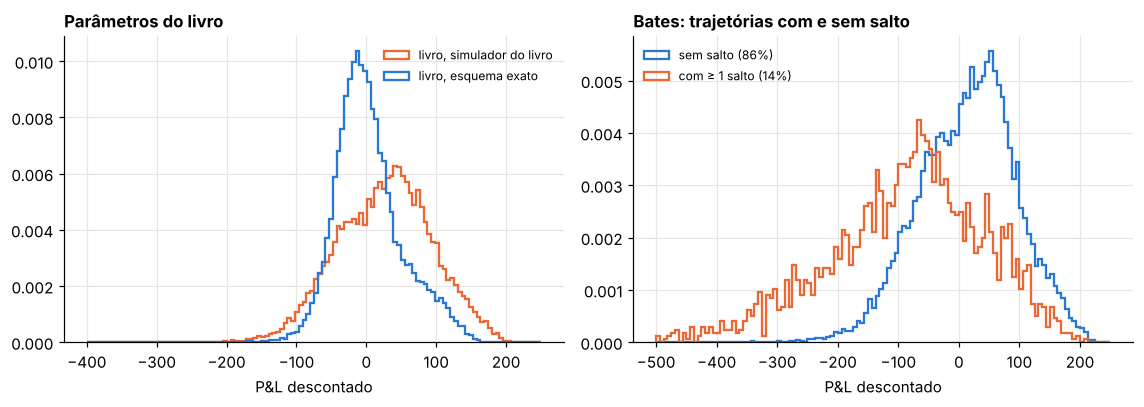

OK — com o simulador do livro, o P&L médio é positivo e significativo, como no livro
OK — livro, esquema exato: o P&L médio é zero, como manda a teoria
OK — Bates, esquema exato: o P&L médio é zero, como manda a teoria
OK — o simulador do livro também infla o preço da put
Bates — dp do P&L com salto: 129,772 | sem salto: 79,194
OK — no Bates, o P&L das trajetórias com salto tem dispersão pelo menos 50% maior


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.8))
for nome, cor in [("livro, simulador do livro", LARANJA), ("livro, esquema exato", AZUL)]:
    axs[0].hist(pls[nome][0], bins=120, range=(-400, 250), histtype="step", lw=1.5, color=cor, label=nome, density=True)
axs[0].set_xlabel("P&L descontado"); axs[0].set_title("Parâmetros do livro"); axs[0].legend(fontsize=8)
pl, Ns = pls["Bates, esquema exato"]
for n, cor in [(0, AZUL), (1, LARANJA)]:
    sel = Ns == 0 if n == 0 else Ns > 0
    axs[1].hist(pl[sel], bins=120, range=(-500, 250), histtype="step", lw=1.5, color=cor, density=True,
                label=("sem salto" if n == 0 else "com ≥ 1 salto") + f" ({100 * sel.mean():.0f}%)")
axs[1].set_xlabel("P&L descontado"); axs[1].set_title("Bates: trajetórias com e sem salto"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

t4 = tab4.set_index("caso")
ok(t4.loc["livro, simulador do livro", "P&L médio"] > 5 * t4.loc["livro, simulador do livro", "erro-padrão"],
   "com o simulador do livro, o P&L médio é positivo e significativo, como no livro")
for c in ["livro, esquema exato", "Bates, esquema exato"]:
    ok(abs(t4.loc[c, "P&L médio"]) < 3 * t4.loc[c, "erro-padrão"] + 0.5, f"{c}: o P&L médio é zero, como manda a teoria")
ok(t4.loc["livro, simulador do livro", "preço LSM"] > t4.loc["livro, esquema exato", "preço LSM"] + 5,
   "o simulador do livro também infla o preço da put")
dp_salto = pl[Ns > 0].std(); dp_sem = pl[Ns == 0].std()
print("Bates — dp do P&L com salto:", f3(dp_salto), "| sem salto:", f3(dp_sem))
ok(dp_salto > 1.5 * dp_sem, "no Bates, o P&L das trajetórias com salto tem dispersão pelo menos 50% maior")

**O que aprendemos.**

* Com a simulação certa, o P&L médio é zero: não há lucro sistemático a colher. O "lucro" do livro mede o quanto o índice simulado deixou de ser martingal.
* A assimetria (mediana positiva, cauda esquerda longa) é real e é, em boa parte, o retrato do risco de salto (o restante da dispersão, também nas trajetórias sem salto, é risco de volatilidade, que a Seção 5 separa): na maioria das trajetórias o hedge ganha um pouco; nas que têm salto, perde muito. Merton (1976) supõe que o risco de salto é **diversificável entre ativos** e, por isso, não precificado; isso não quer dizer que um livro de opções vendidas o elimine. Somar muitas cópias da mesma put sobre o mesmo índice não diversifica nada: os saltos são os mesmos.

---
## 5. Que risco o delta deixa: vol, saltos e o hedge com opções

**Livro: §13.3 (parte final) e §13.4**

O livro conclui que, para hedgear de verdade, é preciso acrescentar outras opções à carteira. Medimos isso para uma put **europeia** no dinheiro de 1 ano (para separar o efeito do hedge do efeito do exercício), com juros constantes de 3%, 50 rebalanceamentos e 10.000 trajetórias, em três mundos:

* **BSM** com $\sigma = \sqrt{\theta_v} = 20\%$;
* **Heston**: o Bates sem saltos;
* **Bates**: o modelo completo dos Módulos 13 a 15.

E duas estratégias:

* **delta**: índice + título;
* **delta-vega**: índice + título + uma put de 18 meses no dinheiro, na quantidade que anula a sensibilidade à variância $v$ (a "vega" do modelo), e índice para anular o delta da carteira. A quantidade da put de hedge é limitada a 3 por put vendida, para que trajetórias extremas (variância perto de zero, em que as duas sensibilidades somem) não gerem posições absurdas.

Preços e gregas no Heston e no Bates vêm da fórmula de Lewis. Para não recalcular a integral para cada trajetória e cada data, montamos em cada data uma **tabela** de preços numa grade de $(v, \ln S/K)$, usando que a função característica não depende de $S$, e interpolamos por splines cúbicos. A tabela é conferida contra a fórmula direta.

### Laboratório 5 — Decompor o erro de hedge

In [7]:
R5, T5, T_H = 0.03, 1.0, 1.5
U5 = np.linspace(0, 400, 4001)
W5 = np.full(len(U5), U5[1] - U5[0]); W5[[0, -1]] /= 2
XG = np.linspace(-1.5, 1.0, 201)
VG = np.linspace(0.0, 0.5, 101)


def tabela_put(tau, p):
    """Put/K na grade (v, x = ln S/K) pela fórmula de Lewis; a função característica é calculada uma vez por v."""
    kappa, theta, sigma, rho, v0, lam, mu, delta = p
    phi = cf_heston(U5[None, :] - 0.5j, tau, VG[:, None], kappa, theta, sigma, rho)
    if lam > 0:
        phi = phi * cf_saltos(U5[None, :] - 0.5j, tau, lam, mu, delta)
    E = np.exp(1j * U5[None, :] * (XG + R5 * tau)[:, None])
    integral = ((phi * W5 / (U5**2 + 0.25)) @ E.T).real
    s = np.exp(XG)[None, :]
    C = s - np.sqrt(s) * np.exp(-0.5 * R5 * tau) / np.pi * integral
    return RegularGridInterpolator((VG, XG), C - s + np.exp(-R5 * tau), method="cubic", bounds_error=False, fill_value=None)


def gregas(f, S, v, K):
    """Preço, delta e sensibilidade a v pela tabela interpolada."""
    x = np.clip(np.log(S / K), XG[0] + 0.01, XG[-1] - 0.01); hx, hv = 1e-3, 1e-4   # nunca extrapola a grade
    v = np.clip(v, 0.0, VG[-1] - hv)
    vv = np.clip(v, hv, VG[-1] - hv)
    P = f(np.column_stack([v, x]))
    dx = (f(np.column_stack([v, x + hx])) - f(np.column_stack([v, x - hx]))) / (2 * hx)
    dv = (f(np.column_stack([vv + hv, x])) - f(np.column_stack([vv - hv, x]))) / (2 * hv)
    return K * P, K * dx / S, K * dv


# conferência da tabela contra a fórmula direta
p_t = BATES
f_t = tabela_put(0.5, p_t)
S_t = np.array([2900.0, S0, 3500.0]); v_t = np.array([0.02, 0.03, 0.05])
tab_vals = gregas(f_t, S_t, v_t, S0)[0]
dir_vals = np.array([calls(Si, [S0], [0.5], [R5], (vi, *p_t[:4]), tuple(p_t[5:]), U_FINO)[0] - Si + S0 * np.exp(-R5 * 0.5)
                     for Si, vi in zip(S_t, v_t)])
print("tabela:", [f3(x) for x in tab_vals], "| fórmula:", [f3(x) for x in dir_vals])
ok(np.abs(tab_vals - dir_vals).max() < 0.05, "a tabela interpolada reproduz a fórmula de Lewis a menos de 0,05 ponto")

tabela: ['309,383', '148,593', '96,785'] | fórmula: ['309,363', '148,590', '96,783']
OK — a tabela interpolada reproduz a fórmula de Lewis a menos de 0,05 ponto


In [8]:
CIR_CONST = dict(r0=R5, kappa=0.0, theta=R5, sigma=0.0)
M5, I5 = 50, 10_000
dt5 = T5 / M5


def hedge_europeia(p, estrategia, rng):
    S, v, _, Ns = simular(p, T5, M5, I5, rng, cir=CIR_CONST)
    alvo = [tabela_put(T5 - j * dt5, p) for j in range(M5)]
    inst = [tabela_put(T_H - j * dt5, p) for j in range(M5 + 1)]

    def posicao(j):
        P, dP, vP = gregas(alvo[j], S[j], v[j], S0)
        H, dH, vH = gregas(inst[j], S[j], v[j], S0)
        with np.errstate(divide="ignore", invalid="ignore"):
            n = np.zeros(I5) if estrategia == "delta" else np.nan_to_num(np.clip(vP / vH, 0.0, 3.0))   # posição limitada
        return P, H, dP - n * dH, n

    P, H, d, n = posicao(0)
    B = P - d * S[0] - n * H
    for j in range(1, M5 + 1):
        B = B * np.exp(R5 * dt5)
        H = gregas(inst[j], S[j], v[j], S0)[0]
        port = d * S[j] + n * H + B
        if j < M5:
            _, _, d_novo, n_novo = posicao(j)
            B = port - d_novo * S[j] - n_novo * H
            d, n = d_novo, n_novo
    return (port - np.maximum(S0 - S[-1], 0)) * np.exp(-R5 * T5), Ns


def hedge_bsm_mundo(rng):
    sig = np.sqrt(BATES[1])
    S = np.full(I5, S0)
    d = delta_put_bsm(S, S0, T5, R5, sig)
    B = put_bsm(S0, S0, T5, R5, sig) - d * S
    for j in range(1, M5 + 1):
        S = S * np.exp((R5 - 0.5 * sig**2) * dt5 + sig * np.sqrt(dt5) * rng.standard_normal(I5))
        B = B * np.exp(R5 * dt5)
        port = d * S + B
        if j < M5:
            d_novo = delta_put_bsm(S, S0, T5 - j * dt5, R5, sig)
            B = port - d_novo * S
            d = d_novo
    return (port - np.maximum(S0 - S, 0)) * np.exp(-R5 * T5)


HESTON_SO = BATES.copy(); HESTON_SO[5] = 0.0
t0 = time.time()
resultados5 = {("BSM", "delta"): (hedge_bsm_mundo(np.random.default_rng(5)), None)}
for mundo, p in [("Heston", HESTON_SO), ("Bates", BATES)]:
    for estr in ("delta", "delta-vega"):
        resultados5[(mundo, estr)] = hedge_europeia(p, estr, np.random.default_rng(5))
print(f"tempo: {time.time() - t0:.1f} s")
linhas = []
for (mundo, estr), (pl, Ns) in resultados5.items():
    com = pl[Ns > 0].std() if Ns is not None and (Ns > 0).sum() > 1 else np.nan
    sem = pl[Ns == 0].std() if Ns is not None else np.nan
    linhas.append((mundo, estr, pl.mean(), pl.std(), np.percentile(pl, 1), pl.min(), com, sem))
tab5 = pd.DataFrame(linhas, columns=["mundo", "estratégia", "P&L médio", "dp", "percentil 1%", "mínimo",
                                     "dp com salto", "dp sem salto"])
tabela(tab5)

tempo: 31.1 s


,mundo,estratégia,P&L médio,dp,percentil 1%,mínimo,dp com salto,dp sem salto
0,BSM,delta,"0,094","30,408","-83,352","-217,601",n/d,n/d
1,Heston,delta,"0,984","77,303","-214,426","-367,200",n/d,"77,303"
2,Heston,delta-vega,"0,195","16,476","-51,655","-183,150",n/d,"16,476"
3,Bates,delta,"1,194","95,423","-320,003","-724,297","136,450","77,108"
4,Bates,delta-vega,"0,251","32,221","-103,448","-597,051","70,676","16,804"


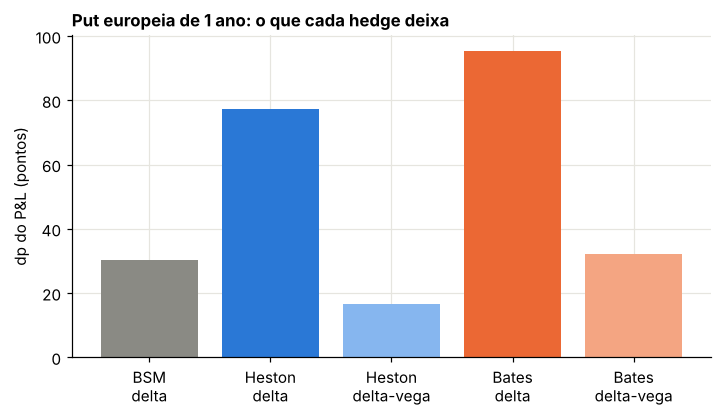

OK — no Heston, o delta sozinho deixa mais que o dobro do erro do BSM: risco de volatilidade
OK — a opção de 18 meses corta o erro do Heston pela metade ou mais
OK — no Bates, o que sobra depois do delta-vega está concentrado nas trajetórias com salto
OK — mesmo assim, a opção também reduz o erro total no Bates


In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
rot = [f"{m}\n{e}" for m, e in zip(tab5["mundo"], tab5["estratégia"])]
ax.bar(rot, tab5["dp"], color=[CINZA, AZUL, RAMPA[0], LARANJA, "#f4a582"])
ax.set_ylabel("dp do P&L (pontos)")
ax.set_title("Put europeia de 1 ano: o que cada hedge deixa")
plt.show()

t5 = tab5.set_index(["mundo", "estratégia"])
ok(t5.loc[("Heston", "delta"), "dp"] > 2 * t5.loc[("BSM", "delta"), "dp"], "no Heston, o delta sozinho deixa mais que o dobro do erro do BSM: risco de volatilidade")
ok(t5.loc[("Heston", "delta-vega"), "dp"] < 0.5 * t5.loc[("Heston", "delta"), "dp"], "a opção de 18 meses corta o erro do Heston pela metade ou mais")
ok(t5.loc[("Bates", "delta-vega"), "dp com salto"] > 2 * t5.loc[("Bates", "delta-vega"), "dp sem salto"],
   "no Bates, o que sobra depois do delta-vega está concentrado nas trajetórias com salto")
ok(t5.loc[("Bates", "delta-vega"), "dp"] < t5.loc[("Bates", "delta"), "dp"], "mesmo assim, a opção também reduz o erro total no Bates")

**O que aprendemos.**

* No BSM, o delta resolve. No Heston, o delta deixa o **risco de volatilidade**: a variância muda, e o índice sozinho não protege contra isso. Uma segunda opção, dimensionada para anular a sensibilidade a $v$, leva o erro para **abaixo** até do BSM só com delta (Módulo 11: o Heston fica completo com uma opção a mais). A opção de hedge também reduz o gama da carteira, e com ele o erro de rebalanceamento discreto.
* No Bates sobra o **risco de salto**. A opção de prazo maior ajuda, porque é convexa e ganha quando o índice salta, mas não cobre o salto: o tamanho é aleatório, e nenhuma quantidade finita de instrumentos replica todos os tamanhos possíveis (§11.2.1). É a incompletude "no sentido amplo" do livro, agora medida.

---
## 6. Síntese do curso

### 6.1 O que os 16 módulos construíram

| Módulo | Ferramenta | Pergunta que responde |
|---|---|---|
| 1 | avaliação baseada em mercado | por que preços de opções e não modelos? |
| 2 | fatos estilizados, vol. implícita | o que um modelo precisa reproduzir? |
| 3-4 | neutralidade ao risco, Itô, Girsanov | por que descontar a esperança sob $Q$? |
| 5-6 | BSM, árvore CRR | o caso de referência e sua aproximação discreta |
| 7-8 | Lewis, Carr-Madan, FFT | como precificar com a função característica |
| 9 | LSM e dual | como tratar o exercício antecipado |
| 10 | Merton | saltos e o primeiro ajuste a mercado |
| 11 | BCC97 | o modelo geral e a estrutura afim |
| 12 | Monte Carlo | discretização, viés e ruído |
| 13-14 | calibração | escolher $Q$ com os preços observados, e o que fica indeterminado |
| 15 | simulação no BCC97 | juntar tudo e conferir pela martingal |
| 16 | hedge dinâmico | o que o modelo protege e o que não protege |

### 6.2 Os testes que se mostraram mais úteis

Ao longo do curso, as mesmas poucas conferências pegaram quase todos os problemas do livro:

1. **Martingal**: $\mathbb{E}^Q[e^{-\int r}S_T] = S_0$. Pegou o `v[t]` (Módulos 12 e 15), o compensador ausente (Módulo 15) e o "lucro" do hedge (Módulo 16).
2. **Duas formas de calcular a mesma coisa**: Fourier contra Monte Carlo, árvore contra LSM, derivada numérica contra fórmula. Pegou a taxa a termo do CIR (Módulo 13), a função característica impressa (Módulo 13) e as referências bermudanas (Módulo 9).
3. **Dados sintéticos com verdade conhecida**: calibrar onde se sabe a resposta. Mostrou a armadilha de Feller, a calibração sequencial que perde os saltos e a degenerescência (Módulos 13 e 14).
4. **Erro-padrão em todo número de Monte Carlo**: separa viés de ruído e evita conclusões sobre o "número de passos" (Módulo 15).

### 6.3 Para continuar

* **Esquemas melhores** para a variância: o QE de Andersen (Módulo 12, exercício 5) e a simulação exata de Broadie e Kaya.
* **Calibração global**: multi-start, `differential_evolution`, e regularização com $w$ escolhido por validação (Módulo 14).
* **Hedge com custos de transação** e frequência ótima de rebalanceamento (Whalley e Wilmott).
* **Volatilidade local e estocástica-local**, que reproduzem a superfície inteira por construção.

## 7. Erratas e notas sobre os capítulos 13 e 14

| Onde | O quê |
|---|---|
| §13.5.1 e §13.5.3, delta inicial | os dois preços LSM da diferença finita usam números aleatórios diferentes: o delta inicial é dominado pelo ruído (desvio-padrão acima de 0,5) |
| §13.5.1, regra de exercício | `h >= C` com `C` truncado em zero marca como exercidas puts fora do dinheiro, encerrando o hedge antes da hora |
| §13.5.2 | P&L calculado nas mesmas trajetórias da regressão (dentro da amostra), apesar de a nota 3 defender a avaliação fora da amostra |
| §13.3, P&L médio de +4,34 | numa simulação sob $Q$, o P&L médio de um hedge autofinanciável iniciado no preço justo é zero; o valor positivo vem do simulador (Módulo 15) |
| §13.3, "risco de salto diversificável" | a hipótese de Merton é de diversificação entre ativos; não vale para muitas opções sobre o mesmo índice, cujos saltos são comuns |
| §13.5.3 | herda o simulador do cap. 12 (`v[t]`, compensador ausente, saltos aditivos, casamento de momentos) |
| Cap. 14 | o resumo é fiel ao livro; os módulos 12 a 16 mostram que as etapas de simulação, calibração e hedge precisam das conferências da Seção 6.2 |

## 8. Exercícios

**Exercício 1.** Prove o Passo 3 da Seção 1 num modelo de um período: com $\Pi_1 = \Delta S_1 + (\Pi_0 - \Delta S_0)(1 + r)$, mostre que $\mathbb{E}^Q[\Pi_1/(1 + r)] = \Pi_0$ para qualquer $\Delta$.

<details><summary>Solução</summary>

$\mathbb{E}^Q[\Pi_1]/(1 + r) = \Delta\,\mathbb{E}^Q[S_1]/(1 + r) + \Pi_0 - \Delta S_0 = \Delta S_0 + \Pi_0 - \Delta S_0 = \Pi_0$, porque $\mathbb{E}^Q[S_1] = S_0(1 + r)$. O delta não entra na média; só na variância.
</details>

**Exercício 2.** No Laboratório 1, troque o delta exato por um delta calculado com a volatilidade errada (25% em vez de 20%). O que acontece com a média e com o desvio-padrão do P&L?

<details><summary>Solução</summary>

Se o preço inicial também for o de 25%, a média do P&L fica positiva: vendeu-se a put cara num mundo de 20%. O ganho esperado é a diferença de preço, $P(25\%) - P(20\%)$, acumulada ao longo do caminho em proporção ao gama. O desvio-padrão aumenta pouco: o delta é pouco sensível à volatilidade perto do dinheiro.
</details>

**Exercício 3.** No Laboratório 5, troque a estratégia delta-vega por delta-gama (mesma put de 18 meses, quantidade que anula o gama). Por que o resultado pode ficar **pior** perto do vencimento?

<details><summary>Solução</summary>

O gama da put de 1 ano no dinheiro explode perto do vencimento, enquanto o da put de 18 meses continua moderado. A razão de gamas, e portanto a posição na opção de hedge, cresce sem limite. Pequenos erros de modelo viram perdas grandes. Na prática, limita-se a posição ou troca-se o instrumento por um de vencimento mais próximo.
</details>

**Exercício 4.** Repita o Laboratório 4 com o hedge **dentro da amostra** (as mesmas trajetórias da regressão). O desvio-padrão do P&L muda?

<details><summary>Solução</summary>

Dentro da amostra, a regra de exercício usa informação das próprias trajetórias, e a regressão foi ajustada a elas: o P&L sai um pouco mais favorável e menos disperso. A diferença é pequena com 50.000 trajetórias, mas cresce com menos trajetórias ou mais funções de base.
</details>

In [10]:
print(f"Módulo 16 concluído: {_checks['n']} verificações aprovadas.")

Módulo 16 concluído: 20 verificações aprovadas.
